# Wavefield · Pseudoelastic pure P-mode (`PseudoelasticP`)

`PseudoelasticP` is the pure P-mode pseudoelastic wave equation of Sun and
Alkhalifah (2021): the 2-D elastic velocity–stress equations in which the
particle velocity is replaced by its curl-free part after every velocity
update. It takes the elastic models `vp`, `vs`, `rho` and radiates **no S wave
and no P–S / S–P conversion** — the grid is set by the P wavelength alone —
while the PP reflections keep the elastic amplitude variation with angle,
because `vs` still enters the stress update through the shear modulus. It
runs on the eager backend (`impl='eager'`), with the same CPML, sources,
receivers and image-method free surface (water top) as `Elastic`; see the
API page for the equation and its limits.

This notebook puts `Elastic` and `PseudoelasticP` side by side on one
three-layer model and one vertical-force source.

## 1. Parameters

In [1]:
import warnings
import numpy as np
import torch
import matplotlib.pyplot as plt

warnings.filterwarnings('ignore', message='Torchinductor does not support.*')

from sweep.equations import Elastic, PseudoelasticP
from sweep.propagator.torch import PropTorch
from sweep.signal import ricker

shape = (600, 400)             # 3 km deep x 2 km wide at 5 m spacing
dh    = 5.0
dt    = 0.5e-3
nt    = 2001
abcn  = 40
freq, delay = 15.0, 0.08
snapshot_times = [1200, 2000]  # 0.6 s and 1.0 s

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.backends.cudnn.allow_tf32 = False   # eager stencils in full FP32, like impl='c'
print('device:', device)

# three layers: (vp, vs, rho) with interfaces at 1 km and 2 km
vp  = torch.full(shape, 2000.0); vs  = torch.full(shape, 1000.0); rho = torch.full(shape, 1800.0)
vp[200:400], vs[200:400], rho[200:400] = 2500.0, 1200.0, 2150.0
vp[400:],    vs[400:],    rho[400:]    = 3000.0, 1500.0, 2300.0
models = [m.to(device) for m in (vp, vs, rho)]

ppw_s = vs.min().item() / (2.5 * freq) / dh          # S wavelength at ~fmax, for the elastic run
cfl = vp.max().item() * dt / dh
print(f'ppw(S) at fmax = {ppw_s:.1f}   CFL = {cfl:.3f}')
assert ppw_s >= 5.0 and cfl <= 0.5

# one vertical force 10 m below the top, in the middle; one receiver line at the same depth
src_iz, src_ix = 2, shape[1] // 2
sources = np.array([[src_ix, src_iz]], dtype=np.int64)
rec_ix = np.arange(0, shape[1], 4)
receivers = np.stack([rec_ix, np.full_like(rec_ix, src_iz)], -1)[None]

t = np.arange(nt, dtype=np.float32) * dt - delay
wavelet = torch.tensor(ricker(t, f=freq).astype(np.float32), device=device)

device: cuda
ppw(S) at fmax = 5.3   CFL = 0.300


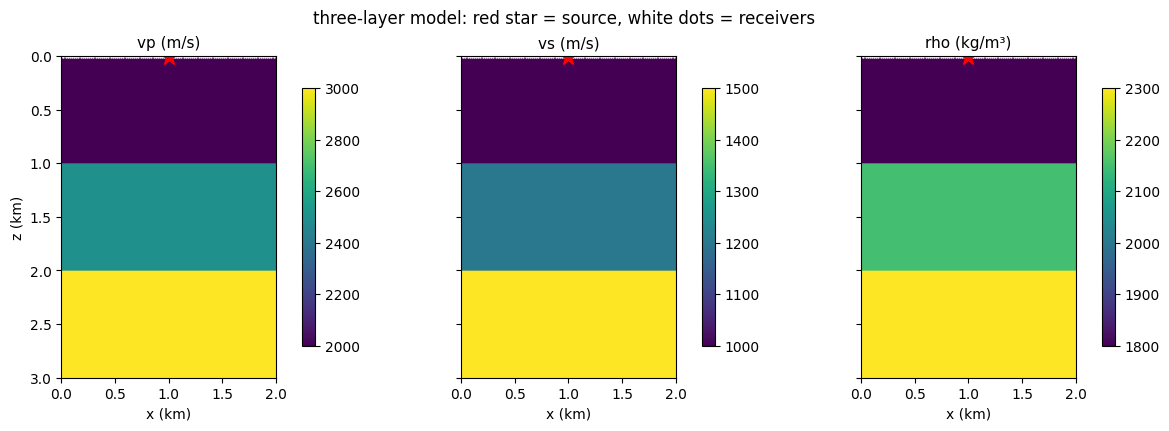

In [2]:
def show_models(vp, vs, rho, src, rec, title):
    extent = [0, vp.shape[1] * dh / 1e3, vp.shape[0] * dh / 1e3, 0]
    fig, axes = plt.subplots(1, 3, figsize=(12, 4.2), constrained_layout=True, sharey=True)
    for ax, m, name, unit in zip(axes, (vp, vs, rho), ('vp', 'vs', 'rho'), ('m/s', 'm/s', 'kg/m³')):
        im = ax.imshow(m.numpy(), cmap='viridis', extent=extent, aspect='equal')
        ax.plot(rec[0, :, 0] * dh / 1e3, rec[0, :, 1] * dh / 1e3, 'w.', ms=1.5)
        ax.plot(src[0, 0] * dh / 1e3, src[0, 1] * dh / 1e3, 'r*', ms=12)
        ax.set_title(f'{name} ({unit})', fontsize=11); ax.set_xlabel('x (km)')
        fig.colorbar(im, ax=ax, shrink=0.8)
    axes[0].set_ylabel('z (km)'); fig.suptitle(title, fontsize=12)
    plt.show()

show_models(vp, vs, rho, sources, receivers, 'three-layer model: red star = source, white dots = receivers')

## 2. Elastic vs pure P-mode: the same model, the same source

Each equation is a drop-in for the other: the same `PropTorch` call, the same
three models. `Elastic` is run on the eager backend too so that both return
snapshots.

In [3]:
runs = {}
for name, eq in (('Elastic', Elastic(device=device)), ('PseudoelasticP', PseudoelasticP(device=device))):
    solver = PropTorch(eq, shape=shape, dh=dh, dt=dt, nt=nt, abcn=abcn,
                       source_type=['vz'], receiver_type=['vz'], impl='eager', use_ckpt=False)
    with torch.no_grad():
        rec, snaps = solver(wavelet, sources, receivers, models=models,
                            return_wavefield=True, snapshot_times=snapshot_times)
    z_lo, z_hi, x_lo, x_hi = solver.pad
    vz = snaps[:, 1, 0, 0].cpu().numpy()            # (snapshot, field, shot, 1, z, x); field 1 = vz
    runs[name] = vz[:, z_lo:vz.shape[1] - z_hi, x_lo:vz.shape[2] - x_hi]
    print(f'{name:15s} snapshots {runs[name].shape}')

sweep: torch.compile is compiling the Elastic step for a 600x400 grid; the first call on each new grid size takes seconds to a few minutes (cached on disk for later runs). EagerOptions(use_compile=False) runs uncompiled instead.


sweep: torch.compile is compiling the PseudoelasticP step for a 600x400 grid


Elastic         snapshots (2, 600, 400)


PseudoelasticP  snapshots (2, 600, 400)


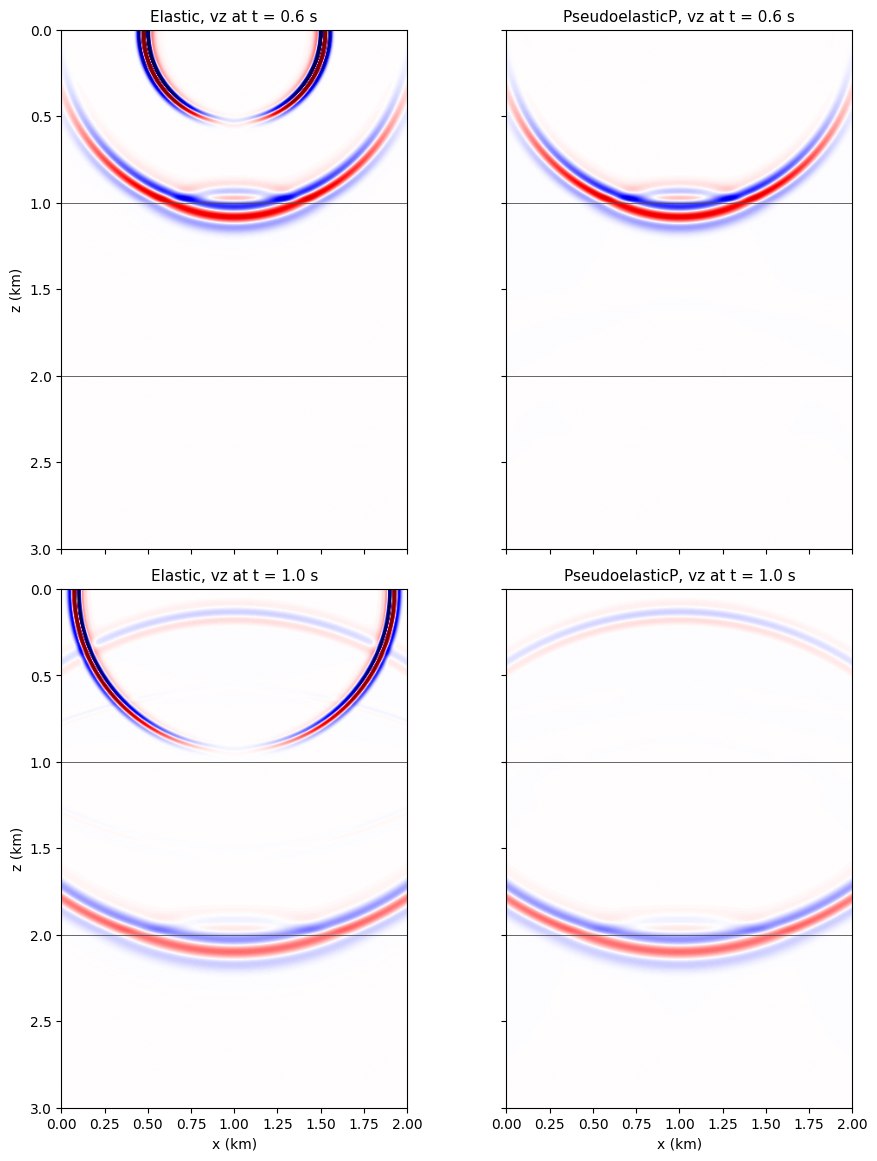

In [4]:
extent = [0, shape[1] * dh / 1e3, shape[0] * dh / 1e3, 0]
fig, axes = plt.subplots(2, 2, figsize=(9, 11.5), constrained_layout=True, sharex=True, sharey=True)
for row, it in enumerate(snapshot_times):
    clip = np.percentile(np.abs(runs['Elastic'][row]), 99.5)
    for col, name in enumerate(runs):
        ax = axes[row, col]
        ax.imshow(runs[name][row], cmap='seismic', vmin=-clip, vmax=clip, extent=extent, aspect='equal')
        for z_km in (1.0, 2.0):
            ax.axhline(z_km, color='0.3', lw=0.6)
        ax.set_title(f'{name}, vz at t = {it * dt:.1f} s', fontsize=11)
for ax in axes[-1]:
    ax.set_xlabel('x (km)')
for ax in axes[:, 0]:
    ax.set_ylabel('z (km)')
plt.show()

Left, `Elastic`: the vertical force radiates P and S; the slow S front sweeps
the top layer and sheds converted waves at the first interface, and each P
front spawns PP and PS. Right, `PseudoelasticP`: the P front with its PP
reflections and transmissions, nothing else — the S front is gone and so are
the conversions. The PP events sit at the same places with the same
amplitudes as on the left (on this model within 1 %), because the shear
modulus still enters the stress update; only the energy that `Elastic` hands
to converted waves stays with P.

## 3. Where it differs from the acoustic equation: a shear-only interface

In a homogeneous medium `PseudoelasticP` and the first-order velocity–stress
acoustic equation are the same thing: for a curl-free velocity
$\nabla\cdot\boldsymbol\tau = (\lambda+2\mu)\nabla(\nabla\cdot\mathbf v) - \mu\nabla\times\nabla\times\mathbf v$
and the second term vanishes, so the P wave travels at `vp` and nothing depends
on `vs`. They differ only where $\mu$ changes. Here `vp` and `rho` are uniform
and only `vs` jumps at 1 km, so the acoustic impedance is continuous: the
acoustic equation (`Elastic` with `vs = 0`, i.e. `sxz = 0` and an isotropic
stress) reflects nothing, while `PseudoelasticP` reflects P with the elastic
AVO of the shear-modulus term — zero at normal incidence, growing with angle
(Aki–Richards: $R \approx -4 (v_s/v_p)^2 \sin^2\theta\, \Delta v_s/v_s$) — like
`Elastic`, which in addition converts part of the energy into PS.

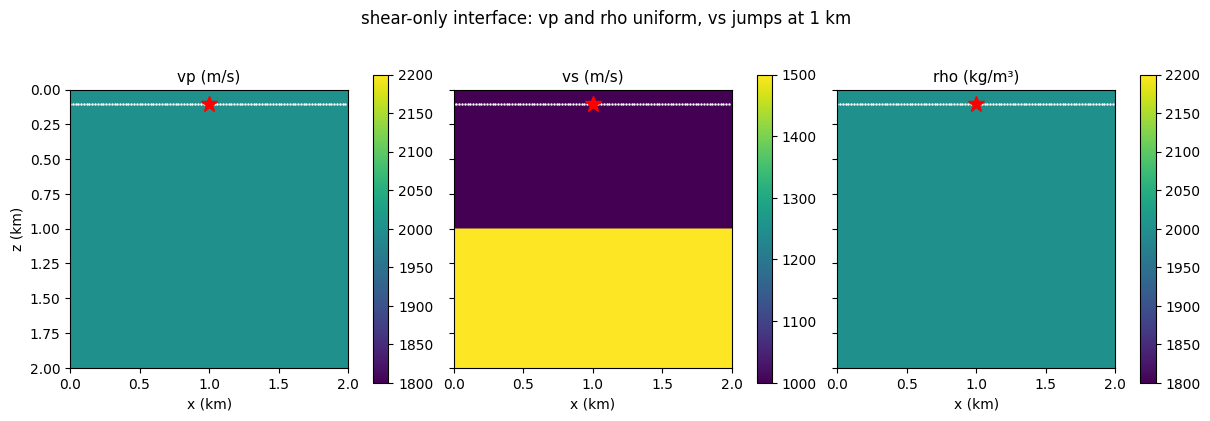

In [5]:
shape3 = (400, 400)                          # 2 km x 2 km at 5 m
nt3, snap3 = 3601, 1800                      # 1.8 s of record, snapshot at 0.9 s
src3_iz = 20                                 # source and receivers 100 m down, clear of the top CPML
vp3  = torch.full(shape3, 2000.0); rho3 = torch.full(shape3, 2000.0)
vs3  = torch.full(shape3, 1000.0); vs3[200:] = 1500.0       # the only contrast, at 1 km

src3 = np.array([[src_ix, src3_iz]], dtype=np.int64)
rec3 = np.stack([rec_ix, np.full_like(rec_ix, src3_iz)], -1)[None]
t3 = np.arange(nt3, dtype=np.float32) * dt - delay
wavelet3 = torch.tensor(ricker(t3, f=freq).astype(np.float32), device=device)
show_models(vp3, vs3, rho3, src3, rec3, 'shear-only interface: vp and rho uniform, vs jumps at 1 km')

sweep: torch.compile is compiling the Elastic step for a 400x400 grid


sweep: torch.compile is compiling the PseudoelasticP step for a 400x400 grid


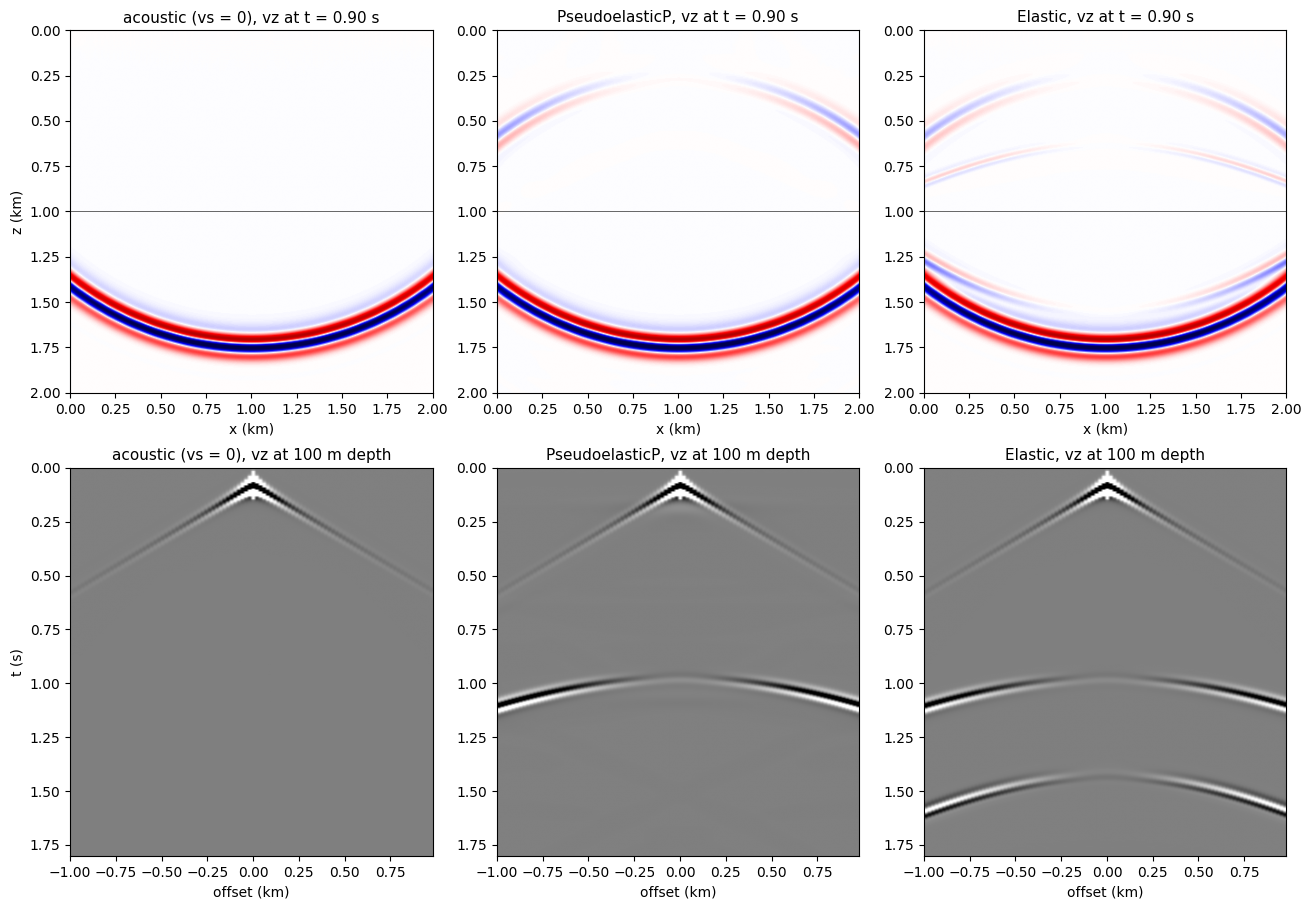

In [6]:
runs3 = {}
for name, eq, vs_m in (('acoustic (vs = 0)', Elastic(device=device), vs3 * 0),
                       ('PseudoelasticP', PseudoelasticP(device=device), vs3),
                       ('Elastic', Elastic(device=device), vs3)):
    solver = PropTorch(eq, shape=shape3, dh=dh, dt=dt, nt=nt3, abcn=abcn,
                       source_type=['sxx', 'szz'], receiver_type=['vz'], impl='eager', use_ckpt=False)
    with torch.no_grad():
        rec, snaps = solver(wavelet3, src3, rec3, models=[m.to(device) for m in (vp3, vs_m, rho3)],
                            return_wavefield=True, snapshot_times=[snap3])
    z_lo, z_hi, x_lo, x_hi = solver.pad
    vz = snaps[0, 1, 0, 0].cpu().numpy()
    runs3[name] = (vz[z_lo:vz.shape[0] - z_hi, x_lo:vz.shape[1] - x_hi], rec[0, :, :, 0].cpu().numpy())

ext3 = [0, shape3[1] * dh / 1e3, shape3[0] * dh / 1e3, 0]
offs = (rec_ix - src_ix) * dh / 1e3
clip_s = np.percentile(np.abs(runs3['acoustic (vs = 0)'][0]), 99.5)
clip_g = np.percentile(np.abs(runs3['Elastic'][1][int(0.9 / dt):]), 99.5)   # after the direct wave
fig, axes = plt.subplots(2, 3, figsize=(13, 9), constrained_layout=True)
for col, (name, (snap, gather)) in enumerate(runs3.items()):
    ax = axes[0, col]
    ax.imshow(snap, cmap='seismic', vmin=-clip_s, vmax=clip_s, extent=ext3, aspect='equal')
    ax.axhline(1.0, color='0.3', lw=0.6); ax.set_title(f'{name}, vz at t = {snap3 * dt:.2f} s', fontsize=11)
    ax.set_xlabel('x (km)')
    ax = axes[1, col]
    ax.imshow(gather, cmap='gray', vmin=-clip_g, vmax=clip_g, aspect='auto',
              extent=[offs[0], offs[-1], nt3 * dt, 0])
    ax.set_title(f'{name}, vz at 100 m depth', fontsize=11); ax.set_xlabel('offset (km)')
axes[0, 0].set_ylabel('z (km)'); axes[1, 0].set_ylabel('t (s)')
plt.show()

Top row, the snapshot at 0.9 s: the transmitted front below the interface
is the same in all three; above it the acoustic panel is empty, while
`PseudoelasticP` and `Elastic` carry the PP reflection from the `vs` jump,
fading to zero straight above the source and growing to the sides.
`Elastic` adds the slower PS front. Bottom row, the surface records: the
acoustic one has only the direct wave, the pure P-mode one the PP
hyperbola with the elastic AVO, `Elastic` the PP hyperbola and the PS
event below it. At a large shear-modulus jump the pure P-mode PP comes out
somewhat stronger than the elastic one (it loses no energy to PS); the
radiation patterns agree to first order (see the API page).